# Fraud / Transaction Risk Detection (UneeQ Interns ML Task)

**Business problem.** A finance team wants to **flag suspicious card transactions for human review**.
The model never blocks or declines a payment. It produces a **risk score** with **reasons**, and a fraud analyst decides.

**What this notebook covers (task requirements):**
1. **Imbalanced data:** only ~0.5% of transactions are fraud. We show why accuracy fails and compare imbalance strategies.
2. **Appropriate metrics & threshold comparison:** PR-AUC, precision, recall, and several threshold policies.
3. **Cost / impact:** a dollar cost model for reviews, customer friction and missed fraud.
4. **Model explanation:** SHAP reason codes for every alert, plus global feature importance.

**Data:** [Credit Card Transactions Fraud Detection](https://www.kaggle.com/datasets/kartik2112/fraud-detection) (Kaggle).
* 1.85M **simulated** transactions (Sparkov generator), Jan 2019 – Dec 2020, about 1,000 customers and 693 merchants.
* Because the data is simulated, real-world performance would be lower. Any deployment would need a pilot on real data.

In [1]:
import sys, json, pickle
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from src.features import load, FEATURES
from src.threshold import confusion_at, REVIEW_COST, FRICTION_COST
from src.explain import Explainer

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RED, GREY, DARK = "#0D9488", "#94A3B8", "#111827"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.axisbelow": True, "grid.color": "#94A3B8", "grid.alpha": 0.6, "grid.linestyle": "--", "axes.edgecolor": "#CBD5E1",
                     "axes.labelcolor": "#1F2937", "xtick.color": "#1F2937", "ytick.color": "#1F2937", "font.size": 10})
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)

## 1. Data exploration

In [2]:
df = load()
print(f"{len(df):,} transactions | {df['cc_num'].nunique():,} customers | fraud rate {df['is_fraud'].mean():.2%} "
      f"({df['is_fraud'].sum():,} frauds)")
df.groupby("split").agg(transactions=("is_fraud", "size"), frauds=("is_fraud", "sum"), fraud_rate=("is_fraud", "mean"),
                        start=("time", "min"), end=("time", "max"))

1,852,394 transactions | 999 customers | fraud rate 0.52% (9,651 frauds)


,transactions,frauds,fraud_rate,start,end
split,,,,,
test,555719,2145,0.0039,2020-06-21 12:14:25,2020-12-31 23:59:34
train,1024843,5899,0.0058,2019-01-01 00:00:18,2020-02-28 23:59:45
val,271832,1607,0.0059,2020-03-01 00:02:20,2020-06-21 12:13:37


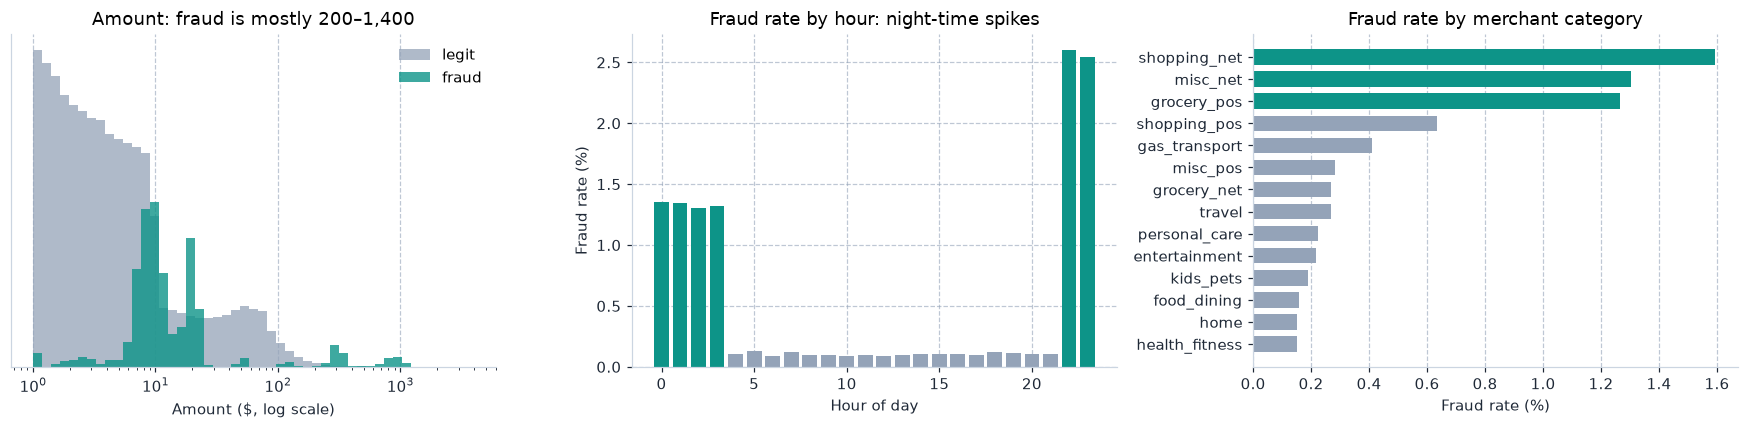

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bins = np.logspace(0, 3.6, 50)
axes[0].hist(df.loc[df.is_fraud == 0, "amt"], bins=bins, color=GREY, alpha=.75, density=True, label="legit")
axes[0].hist(df.loc[df.is_fraud == 1, "amt"], bins=bins, color=RED, alpha=.8, density=True, label="fraud")
axes[0].set(xscale="log", title="Amount: fraud is mostly $200–$1,400", xlabel="Amount ($, log scale)", yticks=[])
axes[0].legend(frameon=False)

hr = df.groupby("hour")["is_fraud"].mean()
axes[1].bar(hr.index, hr.values * 100, color=[RED if (h >= 22 or h < 4) else GREY for h in hr.index])
axes[1].set(title="Fraud rate by hour: night-time spikes", xlabel="Hour of day", ylabel="Fraud rate (%)")

cat = df.groupby("category", observed=True)["is_fraud"].mean().sort_values()
axes[2].barh(cat.index.astype(str), cat.values * 100, color=[RED if v > .007 else GREY for v in cat.values], height=.7)
axes[2].set(title="Fraud rate by merchant category", xlabel="Fraud rate (%)"); axes[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "eda.png", bbox_inches="tight"); plt.show()

In [4]:
cols = ["amt_vs_cust_avg", "amt_last_24h", "txns_last_24h", "hours_since_prev", "is_night"]
df.groupby("is_fraud")[cols].median().rename(index={0: "legit (median)", 1: "fraud (median)"})

,amt_vs_cust_avg,amt_last_24h,txns_last_24h,hours_since_prev,is_night
is_fraud,,,,,
legit (median),0.6653,182.50,3.0,4.3767,0.0
fraud (median),5.2429,1706.97,4.0,1.4031,1.0


**Takeaways:**
* Fraud is **rare**: 0.58% of training data and 0.39% of the test period.
* A typical fraud is **5× the customer's usual amount**, comes **1.4 hours** after the previous purchase (legit: 4.4 hours),
  and follows **$1,700 of spending in 24 hours** (legit: $183). Fraud is a burst of unusual behaviour.
* Night-time hours (10pm–4am) and online shopping or grocery categories carry the highest risk.

## 2. Features without leakage

Every feature uses only what the bank knows **when the transaction happens**: the transaction itself plus that customer's
**past** transactions. Labels are never used, and no future data is used.

| Group | Features |
|---|---|
| Transaction | amount, merchant category (as its historic fraud rate), hour, night-time flag, day of week, distance to merchant |
| Customer | age, home-city population, number of earlier transactions |
| Behaviour (past only) | amount ÷ customer's usual amount, amount ÷ usual amount in this category, first purchase in this category, hours since previous purchase, purchases and spend in the previous 24 hours |

* Names, street, card number and **gender** are not model inputs. Gender is a protected attribute.
* The 24-hour rolling features were checked against a brute-force calculation (0 mismatches on 1,500 rows).
* The time-based split predicts the future:

| Split | Period | Used for |
|---|---|---|
| Train | Jan 2019 – Feb 2020 | fitting the models |
| Validation | Mar – Jun 2020 | choosing the model and the threshold |
| Test | Jun – Dec 2020 | reported once at the end |

## 3. Imbalanced data: the accuracy trap and the strategies

In [5]:
comp = pd.read_csv(ROOT / "reports" / "model_comparison.csv")
te = df[df.split == "test"]
print(f"'Always legit' accuracy on test: {(te.is_fraud == 0).mean():.2%}, yet it catches 0 frauds.")
comp

'Always legit' accuracy on test: 99.61%, yet it catches 0 frauds.


,Model,Imbalance,val_PR_AUC,val_ROC_AUC,train_seconds,test_PR_AUC,test_ROC_AUC
0,Always 'legit' (no model),—,0.0059,0.5000,0.0,0.0039,0.5000
1,Rule: rank by amount,—,0.1891,0.8384,0.0,0.1369,0.8332
2,Logistic regression · balanced weights,weights,0.4238,0.9902,7.4,0.3089,0.9870
3,Gradient boosting · no imbalance handling,none,0.9800,0.9996,29.4,0.9665,0.9992
4,Gradient boosting · balanced weights,weights,0.9806,0.9994,13.3,0.9680,0.9993
5,Gradient boosting · undersampling 1:10,undersample,0.9781,0.9997,10.7,0.9656,0.9994


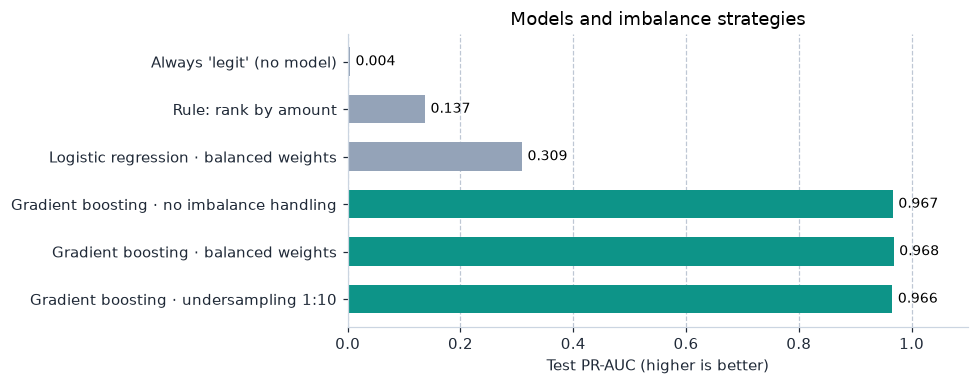

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(comp["Model"], comp["test_PR_AUC"], color=[RED if v > .9 else GREY for v in comp["test_PR_AUC"]], height=.6)
for i, v in enumerate(comp["test_PR_AUC"]):
    ax.text(v + .01, i, f"{v:.3f}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set(xlim=(0, 1.1), xlabel="Test PR-AUC (higher is better)", title="Models and imbalance strategies")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "model_comparison.png", bbox_inches="tight"); plt.show()

* **Accuracy is useless here.** Always predicting "legit" scores 99.6%. We use **PR-AUC**, which focuses on the rare fraud class
  and how well fraud is ranked above legit.
* **The model matters most.** The amount rule (0.14) and logistic regression (0.31) miss the non-linear patterns,
  such as small amounts at night (card testing) or big amounts after a burst of purchases. Gradient boosting captures them (0.97).
* **The imbalance strategies give similar ranking quality:**
  * no handling: 0.966
  * balanced class weights: **0.968** (selected on validation)
  * undersampling 1:10: 0.966, and much faster to train
* Class weights mainly **rescale the scores**, which is why the alert threshold must be tuned separately, on validation data.

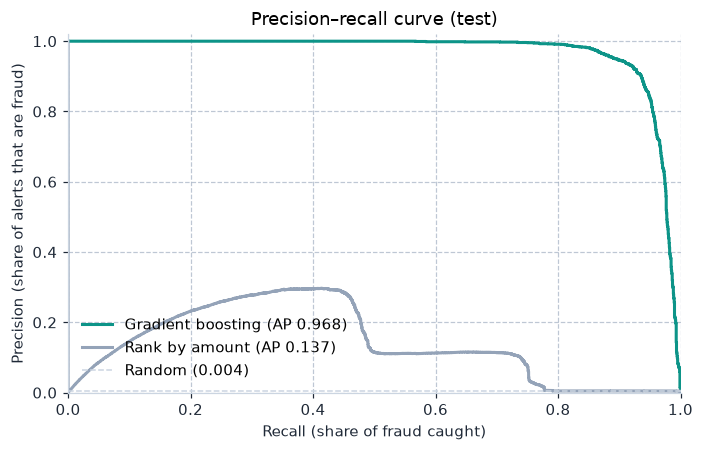

In [7]:
sc = pickle.load(open(ROOT / "data" / "scores.pkl", "rb"))
va, ts = sc[sc.split == "val"], sc[sc.split == "test"]
p, r, _ = precision_recall_curve(ts.is_fraud, ts.score)
pa, ra, _ = precision_recall_curve(ts.is_fraud, ts.amt)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(r, p, color=RED, lw=2, label=f"Gradient boosting (AP {average_precision_score(ts.is_fraud, ts.score):.3f})")
ax.plot(ra, pa, color=GREY, lw=2, label=f"Rank by amount (AP {average_precision_score(ts.is_fraud, ts.amt):.3f})")
ax.axhline(ts.is_fraud.mean(), color="#CBD5E1", ls="--", lw=1, label=f"Random ({ts.is_fraud.mean():.3f})")
ax.set(xlabel="Recall (share of fraud caught)", ylabel="Precision (share of alerts that are fraud)",
       title="Precision–recall curve (test)", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig(FIG / "pr_curve.png", bbox_inches="tight"); plt.show()

## 4. Threshold comparison and cost

Each transaction above the threshold becomes an **alert** that an analyst reviews.

**Cost model** (assumptions, editable in the app):

| Event | Cost |
|---|---|
| Every alert | **$15** of analyst time (about 10 minutes) |
| Every false alarm | **+$10** of customer friction (a call, or a temporary hold) |
| Every missed fraud | its **full amount** (charged back to the bank) |

All thresholds are **chosen on validation data** and reported on test.

In [8]:
tc = pd.read_csv(ROOT / "reports" / "threshold_comparison.csv")
tc[["Policy", "threshold", "alerts_per_day", "precision", "recall", "fraud_$_caught", "fraud_$_missed", "total_cost",
    "savings_vs_no_model"]]

,Policy,threshold,alerts_per_day,precision,recall,fraud_$_caught,fraud_$_missed,total_cost,savings_vs_no_model
0,No model (review nothing),NaN,0.0000,0.0000,0.0000,0.0000e+00,1.1333e+06,1.1333e+06,0.0000e+00
1,Default 0.5,0.5000,13.5773,0.7798,0.9576,1.1153e+06,1.8034e+04,6.3344e+04,1.0700e+06
2,Best F1,0.8900,10.9124,0.9315,0.9193,1.0946e+06,3.8682e+04,7.1887e+04,1.0614e+06
3,Lowest total cost ⭐,0.7600,11.8505,0.8773,0.9403,1.1038e+06,2.9510e+04,6.6815e+04,1.0665e+06
4,Fill team capacity (120/day),0.0028,107.4072,0.1024,0.9949,1.1323e+06,9.8977e+02,5.0057e+05,6.3275e+05


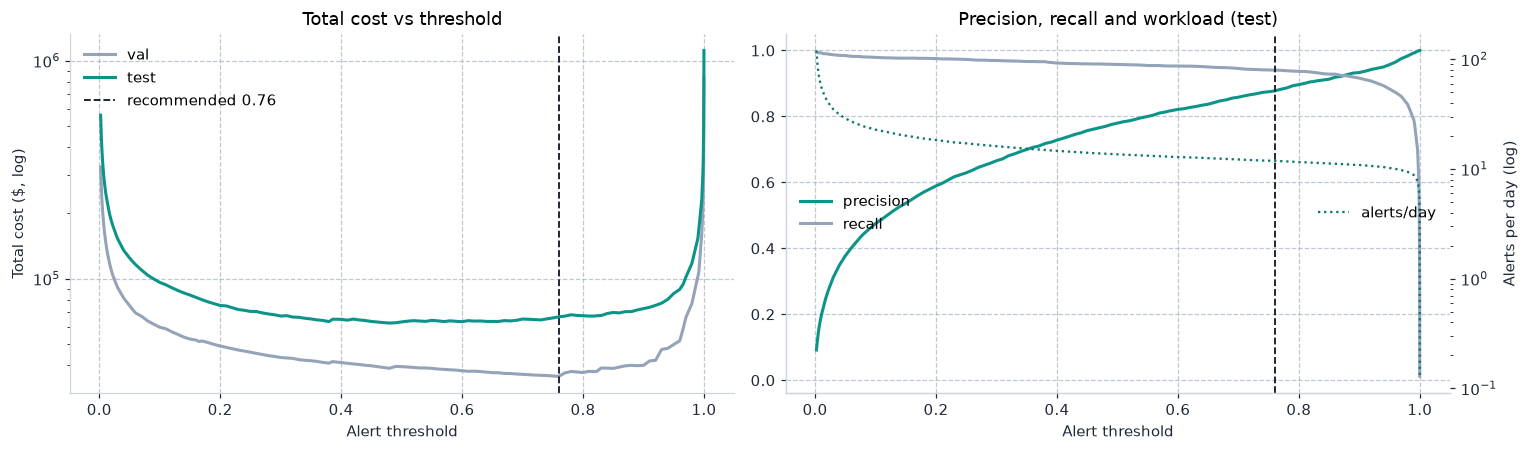

In [9]:
cc = pd.read_csv(ROOT / "reports" / "cost_curve.csv")
rec = json.loads((ROOT / "models" / "threshold.json").read_text())["recommended_threshold"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for split, color in [("val", GREY), ("test", RED)]:
    d = cc[cc.split == split].sort_values("threshold")
    axes[0].plot(d.threshold, d.total_cost, color=color, lw=2, label=split)
axes[0].axvline(rec, color=DARK, ls="--", lw=1.2, label=f"recommended {rec:.2f}")
axes[0].set(yscale="log", xlabel="Alert threshold", ylabel="Total cost ($, log)", title="Total cost vs threshold")
axes[0].legend(frameon=False)
d = cc[cc.split == "test"].sort_values("threshold")
axes[1].plot(d.threshold, d.precision, color=RED, lw=2, label="precision")
axes[1].plot(d.threshold, d.recall, color=GREY, lw=2, label="recall")
ax2 = axes[1].twinx(); ax2.plot(d.threshold, d.alerts_per_day, color="#0F766E", lw=1.5, ls=":", label="alerts/day")
ax2.set(yscale="log", ylabel="Alerts per day (log)"); ax2.grid(False)
axes[1].axvline(rec, color=DARK, ls="--", lw=1.2)
axes[1].set(xlabel="Alert threshold", title="Precision, recall and workload (test)")
axes[1].legend(frameon=False, loc="center left"); ax2.legend(frameon=False, loc="center right")
plt.tight_layout(); plt.savefig(FIG / "threshold_cost.png", bbox_inches="tight"); plt.show()

**Reading the curve:**
* **Very low thresholds** create hundreds of alerts per day, mostly false alarms, so review and friction costs explode.
* **Very high thresholds** miss frauds worth hundreds of dollars each.
* **The minimum is wide and flat (≈ 0.5–0.85),** so the recommendation of **0.76** is robust and doesn't depend on a lucky pick.
* **"Best F1" (0.89)** misses more expensive frauds: F1 counts a missed $900 fraud the same as a false alarm on a $5 coffee.
* **"Filling the team's capacity" (120 alerts/day)** costs about $500K, because extra alerts are mostly false alarms.

### 4b. Sensitivity: does the recommendation change if our cost assumptions are wrong?

In [10]:
y, s, a = va.is_fraud.to_numpy(), va.score.to_numpy(), va.amt.to_numpy()
yt, st_, at = ts.is_fraud.to_numpy(), ts.score.to_numpy(), ts.amt.to_numpy()
grid = np.linspace(0.02, 0.99, 98)
rows = []
for review in [5, 15, 50, 100]:
    for friction in [0, 10, 50]:
        costs = [confusion_at(y, s, a, t, review, friction)["total_cost"] for t in grid]
        t = float(grid[int(np.argmin(costs))])
        m = confusion_at(yt, st_, at, t, review, friction)
        rows.append({"review $/alert": review, "friction $/false alarm": friction, "best threshold (val)": t,
                     "test precision": m["precision"], "test recall": m["recall"], "test total cost": m["total_cost"]})
sens = pd.DataFrame(rows); sens.round(3)

,review $/alert,friction $/false alarm,best threshold (val),test precision,test recall,test total cost
0,5,0,0.38,0.717,0.966,26505.67
1,5,10,0.76,0.877,0.940,43825.09
2,5,50,0.76,0.877,0.940,55105.09
3,15,0,0.76,0.877,0.940,63995.09
4,15,10,0.76,0.877,0.940,66815.09
5,15,50,0.76,0.877,0.940,78095.09
6,50,0,0.76,0.877,0.940,144460.09
7,50,10,0.76,0.877,0.940,147280.09
8,50,50,0.90,0.933,0.916,152243.10
9,100,0,0.90,0.933,0.916,250493.10


The best threshold moves only modestly across a wide range of assumptions.
* **Analyst time expensive** ($100 per alert): the threshold rises slightly, giving fewer alerts.
* **Analyst time cheap** ($5 per alert): it falls, giving more alerts.

The memo recommends **0.76** and a quarterly review.

## 5. Model explanation (SHAP)

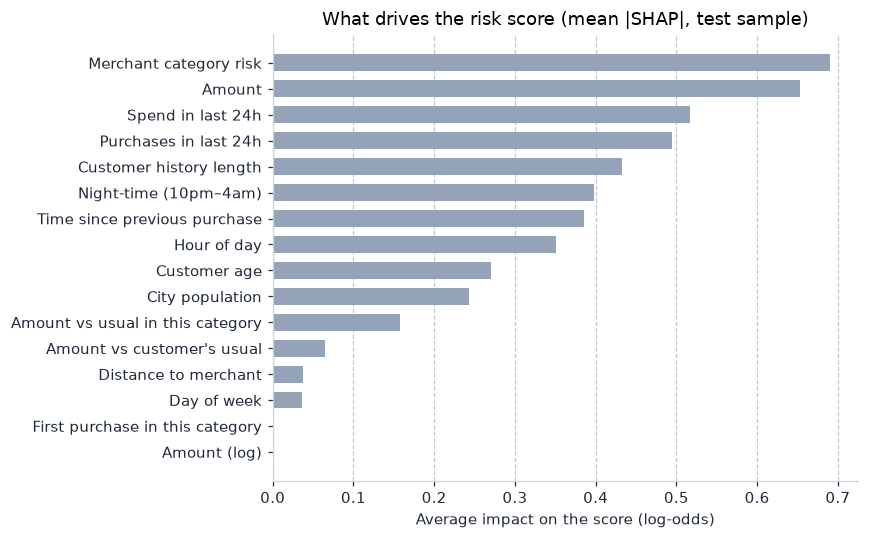

In [11]:
ex = Explainer()
imp = ex.global_importance(ts.sample(6000, random_state=0))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index[::-1], imp.values[::-1], color=GREY, height=.65)
ax.barh(imp.index[-3:][::-1][:0], [])  # keep order
ax.set(title="What drives the risk score (mean |SHAP|, test sample)", xlabel="Average impact on the score (log-odds)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "shap_importance.png", bbox_inches="tight"); plt.show()

In [12]:
q = ts[ts.score >= rec].sort_values("score", ascending=False)
examples = pd.concat([q[q.is_fraud == 1].head(3), q[q.is_fraud == 0].head(2)])
for (_, r), reasons in zip(examples.iterrows(), ex.reasons(examples)):
    label = "FRAUD" if r.is_fraud else "legit (false alarm)"
    print(f"${r.amt:,.2f} · {r.category} · {r.time:%d %b %H:%M} · score {r.score:.3f} · actual: {label}")
    for x in reasons:
        print("    ▸", x["text"])

$302.20 · grocery_pos · 12 Aug 02:17 · score 1.000 · actual: FRAUD
    ▸ Large amount: $302.20
    ▸ $5,202 spent in the previous 24h
    ▸ High-risk category: grocery (in store) (1.4% historic fraud rate)
$288.80 · grocery_pos · 12 Aug 01:05 · score 1.000 · actual: FRAUD
    ▸ Large amount: $288.80
    ▸ $5,176 spent in the previous 24h
    ▸ High-risk category: grocery (in store) (1.4% historic fraud rate)
$325.67 · grocery_pos · 26 Jul 23:33 · score 1.000 · actual: FRAUD
    ▸ Large amount: $325.67
    ▸ $5,228 spent in the previous 24h
    ▸ At 11 PM (night-time)
$774.23 · misc_net · 08 Jul 01:53 · score 0.999 · actual: legit (false alarm)
    ▸ Large amount: $774.23
    ▸ $766 spent in the previous 24h
    ▸ At 1 AM (night-time)
$19.73 · gas_transport · 31 Jul 01:20 · score 0.999 · actual: legit (false alarm)
    ▸ Unusual pattern for gas & transport purchases
    ▸ Small amount ($19.73), a typical card-testing pattern
    ▸ At 1 AM (night-time)


* **Globally,** the merchant category's risk, the amount and the last-24-hour activity dominate.
* **Per alert,** SHAP lists the top factors that pushed *this* transaction's score up. That's what the analyst sees.
  The contributions add up exactly to the model's output, so the reasons are faithful to the model.
* **False alarms are explainable too.** A large night-time online purchase looks risky even when it's genuine,
  which is exactly why a human makes the final call.

## 6. Fairness check (age)

In [13]:
t = ts.assign(age_group=pd.cut(ts.age, [0, 30, 45, 60, 120], labels=["<30", "30–44", "45–59", "60+"]),
              alert=ts.score >= rec)
fair = t.groupby("age_group", observed=True).apply(lambda g: pd.Series({
    "transactions": len(g), "fraud_rate": g.is_fraud.mean(),
    "recall": g.loc[g.is_fraud == 1, "alert"].mean(),
    "false_alarm_rate": g.loc[g.is_fraud == 0, "alert"].mean() * 100}), include_groups=False)
fair.rename(columns={"false_alarm_rate": "false alarms per 100 legit"}).round(4)

,transactions,fraud_rate,recall,false alarms per 100 legit
age_group,,,,
<30,94777.0,0.0033,0.9779,0.0498
30–44,186019.0,0.0035,0.9230,0.0593
45–59,152104.0,0.0040,0.9222,0.0528
60+,122819.0,0.0047,0.9583,0.0368


Age is a model input because spending patterns differ by age, and in this data fraud targets some age groups more.
We check that **recall** (fraud caught) and **false-alarm rates** are reasonably similar across age groups.
* Any large gap should be reviewed before deployment.
* An alternative is to drop age and accept a small loss in accuracy, as we did for gender.

## 7. Conclusions

| Requirement | Result |
|---|---|
| Imbalanced data | Accuracy trap shown (99.6% for "always legit"); weights vs undersampling vs none compared; threshold tuned separately |
| Metrics & thresholds | PR-AUC for model choice; precision, recall, alerts/day and $ cost for 5 threshold policies |
| Cost / impact | Recommended threshold 0.76: **~12 alerts/day, 88% precision, 94% recall, ≈ $1.07M saved** over 6 months vs no model |
| Explanation | SHAP reason codes per alert + global importance; gender excluded; age fairness checked |
| Human review | The model only prioritises a queue. Analysts confirm, release or escalate every alert |

**Limitations:**
* The data is simulated, so real-world performance will be lower.
* Fraud patterns drift over time, so the model needs monitoring and retraining.
* The cost figures are assumptions.
* Scores are risk ranks, not calibrated probabilities.

**Next steps:**
* A shadow-mode pilot on real data.
* Merchant-level features.
* Probability calibration.
* Monitoring precision and recall weekly.